Sujet :  « Anticipations d'inflation »
C'est une régression sur séries mensuelles, avec les algorithmes 1, 2 et 3. Votre fichier est quotidien, donc il faudra l'agréger au mois. Pouvez-vous confirmer que c'est bien F22 ? Sinon, F3 (prévision de l'inflation) est également possible.

**Problématique **: Le niveau des anticipations d'inflation à 10 ans du mois précédent et son historique récent permettent-ils de mieux prévoir le T10YIE du mois suivant qu'une simple persistance ?

Objectif mesurable (fixé avant les résultats) :

Cible : T10YIE moyen du mois t+1.
Variables : valeurs retardées (t, t−1, t−2, …), variation sur 1 mois, moyenne mobile sur 3 mois et volatilité sur 3 mois, toutes calculées uniquement avec le passé.
Découpage chronologique : environ 70 % entraînement, 15 % validation, 15 % test.
Référence naïve : persistance (la valeur du mois t prédit celle de t+1).
Métrique principale : RMSE sur le test. Métrique secondaire : MAE.
Critère de réussite : le modèle est jugé meilleur s’il obtient un RMSE inférieur à celui de la persistance. Sinon, on conclut honnêtement que la série est quasi marche aléatoire.

In [19]:
# Importation des bibliothèques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, learning_curve, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Reproductibilité et style des graphiques
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

In [20]:
# Chargement du jeu de données depuis une URL publique
URL = "/content/drive/MyDrive/test CC fin 2/T10YIE.csv"
df = pd.read_csv(URL)
print("Dimensions :", df.shape)
df.head()

Dimensions : (6222, 2)


,observation_date,T10YIE
0,2003-01-02,1.64
1,2003-01-03,1.62
2,2003-01-06,1.63
3,2003-01-07,1.62
4,2003-01-08,1.71


# **Première exploration**

In [21]:
# Types des colonnes et nombre de valeurs non renseignées
df.info()
print("\nValeurs manquantes par colonne :")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6222 entries, 0 to 6221
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  6222 non-null   object 
 1   T10YIE            5967 non-null   float64
dtypes: float64(1), object(1)
memory usage: 97.3+ KB

Valeurs manquantes par colonne :
observation_date      0
T10YIE              255
dtype: int64


In [22]:
# Conversion de la date et série quotidienne
df["observation_date"] = pd.to_datetime(df["observation_date"])
df = df.sort_values("observation_date").reset_index(drop=True)
daily = df.set_index("observation_date")["T10YIE"]

print("Manquants :", df["T10YIE"].isna().sum(), "| Doublons de dates :", df["observation_date"].duplicated().sum())

# Agrégation mensuelle : les jours fériés (NaN) sont ignorés, pas imputés
monthly = daily.resample("MS").agg(["mean", "std", "count"])
monthly.columns = ["niveau", "vol_intra", "n_jours"]

# Retrait du dernier mois s'il est incomplet
if monthly["n_jours"].iloc[-1] < 15:
    monthly = monthly.iloc[:-1]
print("Mois disponibles :", len(monthly))

Manquants : 255 | Doublons de dates : 0
Mois disponibles : 286


In [23]:
# Statistiques descriptives des variables numériques
df.describe().round(1)

,observation_date,T10YIE
count,6222,5967.0
mean,2014-12-05 02:23:43.336547584,2.1
min,2003-01-02 00:00:00,0.0
25%,2008-12-18 06:00:00,1.9
50%,2014-12-04 12:00:00,2.2
75%,2020-11-19 18:00:00,2.4
max,2026-11-06 00:00:00,3.0
std,NaN,0.4


# E**xploration et prétraitement** : 3 figures commentées, pipeline sans fuite

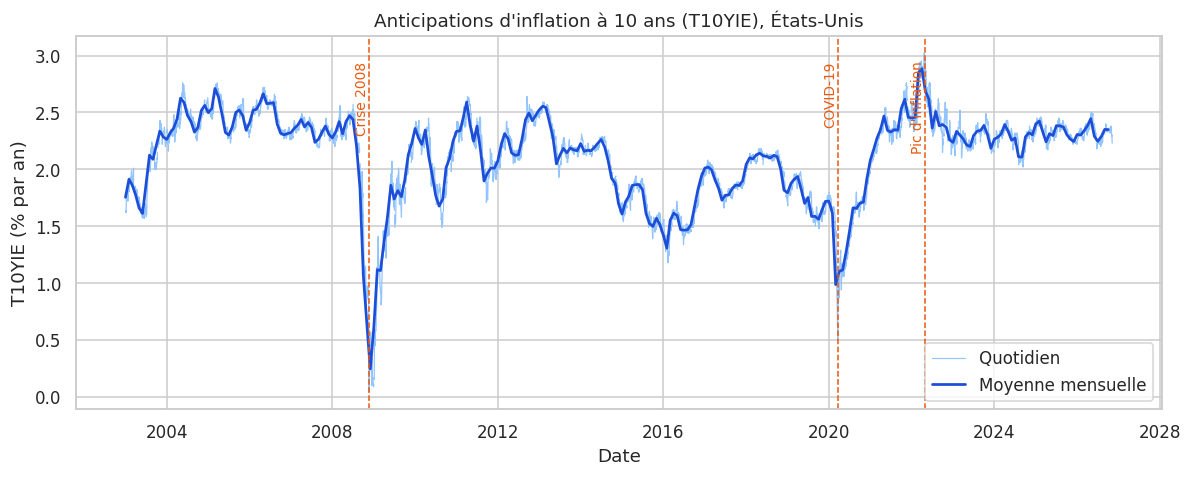

In [24]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily.index, daily.values, color="#93c5fd", lw=0.8, label="Quotidien")
ax.plot(monthly.index, monthly["niveau"], color="#1d4ed8", lw=1.8, label="Moyenne mensuelle")
for date, txt in [("2008-11-20", "Crise 2008"), ("2020-03-19", "COVID-19"), ("2022-04-25", "Pic d'inflation")]:
    ax.axvline(pd.Timestamp(date), color="#ea580c", ls="--", lw=1)
    ax.text(pd.Timestamp(date), 2.95, txt, rotation=90, va="top", ha="right", fontsize=9, color="#ea580c")
ax.set_title("Anticipations d'inflation à 10 ans (T10YIE), États-Unis")
ax.set_xlabel("Date")
ax.set_ylabel("T10YIE (% par an)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Interprétation : la série oscille surtout entre 2 et 2,5 %, proche de la cible de la Fed. Elle s’effondre fin 2008 (près de 0 %), chute en mars 2020, puis remonte avec l’inflation de 2021-2022. Elle n’est pas stationnaire en niveau : les chocs persistent.

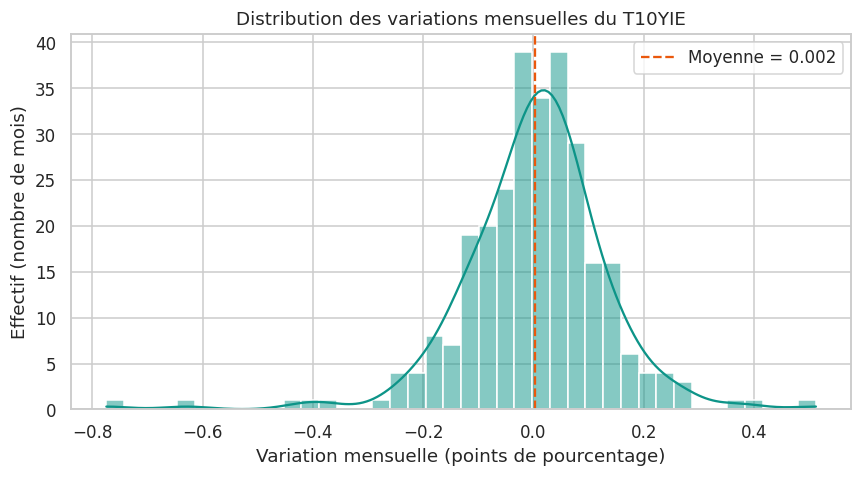

Plus fortes baisses :
 observation_date
2008-10-01   -0.77
2020-03-01   -0.63
2008-11-01   -0.42
Name: niveau, dtype: float64
Plus fortes hausses :
 observation_date
2009-02-01    0.51
2022-03-01    0.39
2009-01-01    0.36
Name: niveau, dtype: float64


In [25]:
var_m = monthly["niveau"].diff().dropna()

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(var_m, bins=40, kde=True, color="#0d9488", ax=ax)
ax.axvline(var_m.mean(), color="#ea580c", ls="--", label=f"Moyenne = {var_m.mean():.3f}")
ax.set_title("Distribution des variations mensuelles du T10YIE")
ax.set_xlabel("Variation mensuelle (points de pourcentage)")
ax.set_ylabel("Effectif (nombre de mois)")
ax.legend()
plt.tight_layout()
plt.show()

print("Plus fortes baisses :\n", var_m.nsmallest(3).round(2))
print("Plus fortes hausses :\n", var_m.nlargest(3).round(2))

Interprétation : les variations sont centrées sur zéro, comme pour une quasi marche aléatoire, mais avec des queues épaisses. Les mois extrêmes sont octobre 2008 (−0,77), mars 2020 (−0,63) et février 2009 (+0,51). Ce sont des événements réels, donc on les conserve. Ils justifient de rapporter aussi la MAE, moins sensible aux gros écarts que la RMSE.

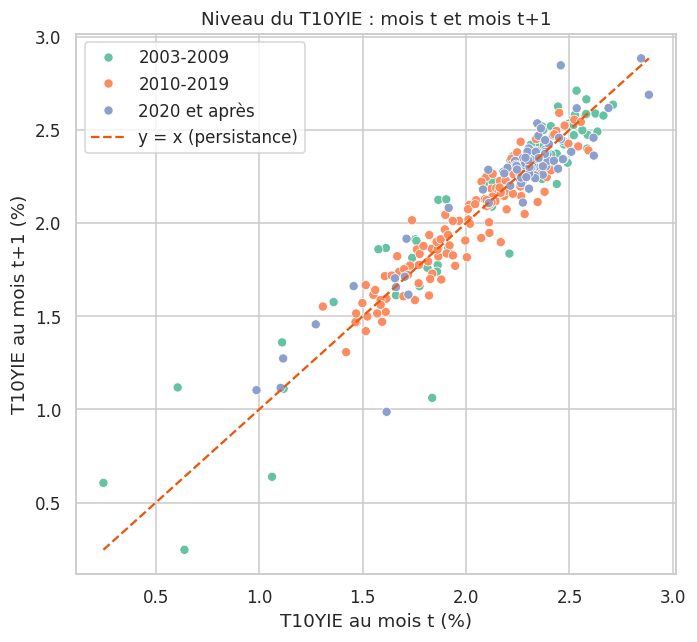

Corrélation t / t+1 : 0.942


In [26]:
tmp = pd.DataFrame({"t": monthly["niveau"], "t_plus_1": monthly["niveau"].shift(-1)}).dropna()
tmp["periode"] = np.where(tmp.index.year < 2010, "2003-2009",
                  np.where(tmp.index.year < 2020, "2010-2019", "2020 et après"))

fig, ax = plt.subplots(figsize=(6.5, 6))
sns.scatterplot(data=tmp, x="t", y="t_plus_1", hue="periode", ax=ax)
lims = [tmp[["t", "t_plus_1"]].min().min(), tmp[["t", "t_plus_1"]].max().max()]
ax.plot(lims, lims, color="#ea580c", ls="--", label="y = x (persistance)")
ax.set_title("Niveau du T10YIE : mois t et mois t+1")
ax.set_xlabel("T10YIE au mois t (%)")
ax.set_ylabel("T10YIE au mois t+1 (%)")
ax.legend()
plt.tight_layout()
plt.show()

print("Corrélation t / t+1 :", round(tmp["t"].corr(tmp["t_plus_1"]), 3))

Interprétation : les points sont très proches de la diagonale, avec une corrélation de 0,94. Le niveau du mois suivant ressemble beaucoup à celui du mois courant, donc la référence naïve (persistance) sera difficile à battre. Les écarts les plus grands se concentrent sur 2008-2009.


# Modèle et évaluation


In [27]:
# Variables construites avec le passé uniquement, cible = niveau du mois suivant
feat = pd.DataFrame(index=monthly.index)
feat["niveau_t"]   = monthly["niveau"]
feat["niveau_t_1"] = monthly["niveau"].shift(1)
feat["niveau_t_2"] = monthly["niveau"].shift(2)
feat["var_1m"]     = monthly["niveau"].diff(1)
feat["ma3"]        = monthly["niveau"].rolling(3).mean()
feat["vol_intra"]  = monthly["vol_intra"]
feat["cible"]      = monthly["niveau"].shift(-1)

data = feat.dropna().copy()
X_cols = ["niveau_t", "niveau_t_1", "niveau_t_2", "var_1m", "ma3", "vol_intra"]

# Découpage chronologique : 70 % entraînement
i_tr = int(len(data) * 0.70)
train = data.iloc[:i_tr]
X_train, y_train = train[X_cols], train["cible"]

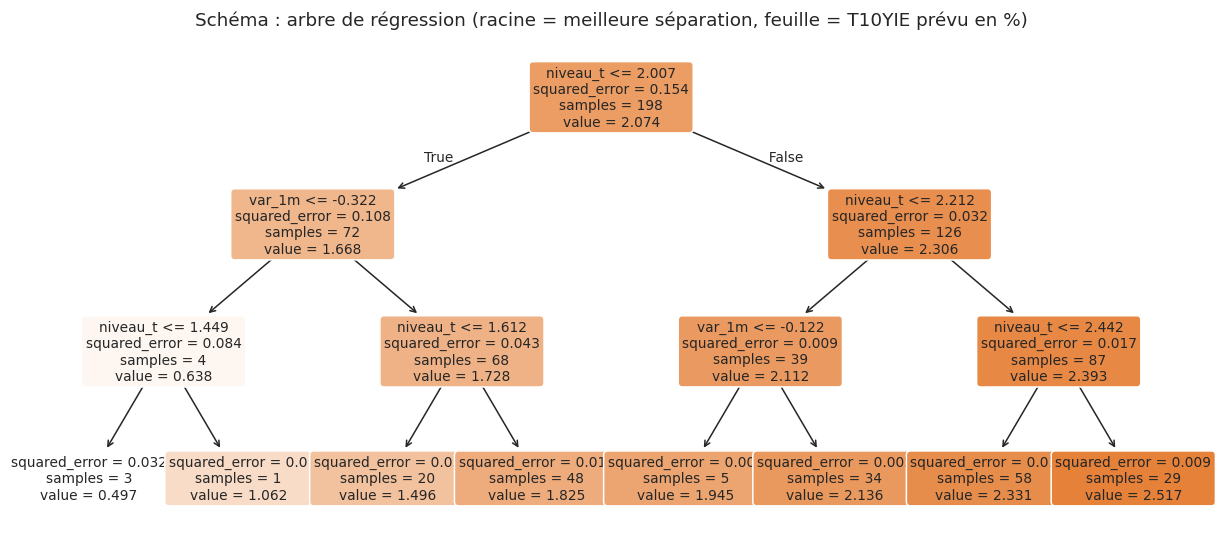

In [28]:
# Schéma : arbre de régression (schéma lisible et légendé)
from sklearn.tree import plot_tree, DecisionTreeRegressor
GRAINE = 42
m = DecisionTreeRegressor(max_depth=3, random_state=GRAINE).fit(X_train, y_train)
plt.figure(figsize=(14, 6))
plot_tree(m, filled=True, feature_names=X_cols, rounded=True, fontsize=9)
plt.title("Schéma : arbre de régression (racine = meilleure séparation, feuille = T10YIE prévu en %)")
plt.show()

# **Expérimenter, comparer et conclure**

In [29]:
# 1. Découpage chronologique 70 % / 15 % / 15 % (aucun mélange des dates)
n = len(data)
i_tr, i_va = int(n * 0.70), int(n * 0.85)
train, val, test = data.iloc[:i_tr], data.iloc[i_tr:i_va], data.iloc[i_va:]
X_tr, y_tr = train[X_cols], train["cible"]
X_va, y_va = val[X_cols], val["cible"]
X_te, y_te = test[X_cols], test["cible"]
for nom, d in [("Entraînement", train), ("Validation", val), ("Test", test)]:
    print(f"{nom:12s}: {len(d):3d} mois | cibles du {d.index[0]:%m/%Y} au {(d.index[-1] + pd.DateOffset(months=1)):%m/%Y}")

def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))
def mae(y, p):  return float(mean_absolute_error(y, p))

Entraînement: 198 mois | cibles du 03/2003 au 09/2019
Validation  :  42 mois | cibles du 09/2019 au 03/2023
Test        :  43 mois | cibles du 03/2023 au 10/2026


In [33]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

# 2. Références naïves : persistance (niveau du mois t) et moyenne de l'entraînement
pers_va, pers_te = X_va["niveau_t"], X_te["niveau_t"]
moy = y_tr.mean()
print(f"\nPersistance : RMSE val = {rmse(y_va, pers_va):.4f} | RMSE test = {rmse(y_te, pers_te):.4f}")
print(f"Moyenne     : RMSE val = {rmse(y_va, np.full(len(y_va), moy)):.4f} | RMSE test = {rmse(y_te, np.full(len(y_te), moy)):.4f}")


Persistance : RMSE val = 0.1581 | RMSE test = 0.0702
Moyenne     : RMSE val = 0.4828 | RMSE test = 0.2402


In [35]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

# 2. Références naïves : persistance (niveau du mois t) et moyenne de l'entraînement
pers_va, pers_te = X_va["niveau_t"], X_te["niveau_t"]
moy = y_tr.mean()
print(f"\nPersistance : RMSE val = {rmse(y_va, pers_va):.4f} | RMSE test = {rmse(y_te, pers_te):.4f}")
print(f"Moyenne     : RMSE val = {rmse(y_va, np.full(len(y_va), moy)):.4f} | RMSE test = {rmse(y_te, np.full(len(y_te), moy)):.4f}")


Persistance : RMSE val = 0.1581 | RMSE test = 0.0702
Moyenne     : RMSE val = 0.4828 | RMSE test = 0.2402


In [36]:
# 3. Réglage d'UN hyperparamètre par modèle, uniquement sur entraînement -> validation
modeles = {
    "Régression Ridge": (lambda a: Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=a))]), "alpha", [0.001, 0.01, 0.1, 1, 10, 100]),
    "Arbre de régression": (lambda d: DecisionTreeRegressor(max_depth=d, random_state=42), "max_depth", [2, 3, 4, 5, 6, 8]),
    "Forêt aléatoire": (lambda d: RandomForestRegressor(n_estimators=200, max_depth=d, min_samples_leaf=3, random_state=42, n_jobs=-1), "max_depth", [2, 3, 4, 6, 8]),
}
resultats, courbes, preds_te = [], {}, {}
for nom, (fabrique, hp, grille) in modeles.items():
    scores = []
    for v in grille:
        m = fabrique(v).fit(X_tr, y_tr)
        scores.append(rmse(y_va, m.predict(X_va)))
    courbes[nom] = (grille, scores)
    best = grille[int(np.argmin(scores))]
    # RMSE d'entraînement et de validation du modèle réglé (signe de surapprentissage)
    m_tr = fabrique(best).fit(X_tr, y_tr)
    r_tr, r_va = rmse(y_tr, m_tr.predict(X_tr)), rmse(y_va, m_tr.predict(X_va))
    # Réestimation sur entraînement + validation, puis évaluation unique sur le test
    m_fin = fabrique(best).fit(pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va]))
    p_te = m_fin.predict(X_te); preds_te[nom] = p_te
    resultats.append({"Modèle": nom, "Hyperparamètre": f"{hp} = {best}", "RMSE train": r_tr, "RMSE val": r_va,
                      "RMSE test": rmse(y_te, p_te), "MAE test": mae(y_te, p_te)})
    print(f"{nom:20s} meilleur {hp} = {best} (RMSE val = {min(scores):.4f})")

Régression Ridge     meilleur alpha = 0.001 (RMSE val = 0.1657)
Arbre de régression  meilleur max_depth = 4 (RMSE val = 0.2004)
Forêt aléatoire      meilleur max_depth = 4 (RMSE val = 0.1670)


                    Hyperparamètre  RMSE train  RMSE val  RMSE test  MAE test
Modèle                                                                       
Régression Ridge     alpha = 0.001      0.1169    0.1657     0.0719    0.0557
Arbre de régression  max_depth = 4      0.0923    0.2004     0.0882    0.0673
Forêt aléatoire      max_depth = 4      0.1009    0.1670     0.0800    0.0604

Modèle retenu (validation) : Régression Ridge


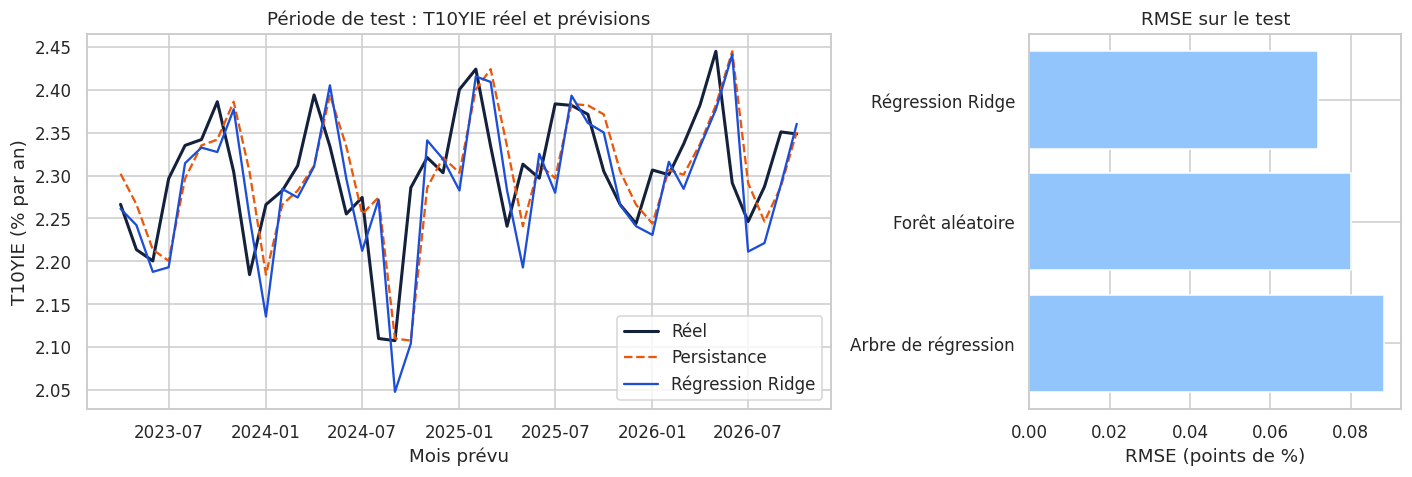

In [39]:
cols = ["RMSE train", "RMSE val", "RMSE test", "MAE test"]
print(tableau[["Hyperparamètre"] + cols].round(4).to_string())

# Modèle retenu = meilleur RMSE de VALIDATION (le test n'est pas utilisé pour choisir)
retenu = tableau.loc[[r["Modèle"] for r in resultats], "RMSE val"].idxmin()
p_mod = pd.Series(preds_te[retenu], index=y_te.index)
p_ref = pers_te
print("\nModèle retenu (validation) :", retenu)
# 5. Figures de résultat
dates = y_te.index + pd.DateOffset(months=1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(dates, y_te.values, color="#14213d", lw=2, label="Réel")
ax[0].plot(dates, p_ref.values, color="#ea580c", ls="--", label="Persistance")
ax[0].plot(dates, p_mod.values, color="#1d4ed8", label=retenu)
ax[0].set_title("Période de test : T10YIE réel et prévisions")
ax[0].set_xlabel("Mois prévu"); ax[0].set_ylabel("T10YIE (% par an)"); ax[0].legend()
ordre = tableau["RMSE test"].sort_values()
ax[1].barh(ordre.index, ordre.values, color=["#ea580c" if "Persistance" in i else "#93c5fd" for i in ordre.index])
ax[1].set_title("RMSE sur le test"); ax[1].set_xlabel("RMSE (points de %)"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

Biais moyen (réel - prévu) : modèle = +0.0157 | persistance = +0.0011
Mois où le modèle est plus précis que la persistance : 49%

Cinq plus grosses erreurs du modèle :
             réel  modèle  persistance  erreur modèle
mois                                                 
2024-10-01  2.286   2.104        2.108          0.182
2024-08-01  2.110   2.272        2.275         -0.162
2026-06-01  2.291   2.441        2.445         -0.150
2024-01-01  2.266   2.136        2.184          0.131
2025-05-01  2.313   2.193        2.241          0.121


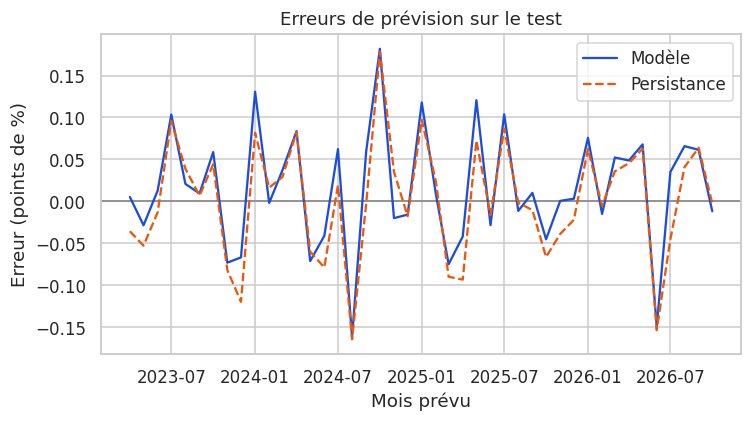

In [40]:
# 6. Analyse des erreurs
e_mod, e_ref = y_te - p_mod, y_te - p_ref
print(f"Biais moyen (réel - prévu) : modèle = {e_mod.mean():+.4f} | persistance = {e_ref.mean():+.4f}")
print(f"Mois où le modèle est plus précis que la persistance : {(e_mod.abs() < e_ref.abs()).mean():.0%}")
pires = pd.DataFrame({"réel": y_te, "modèle": p_mod, "persistance": p_ref, "erreur modèle": e_mod}).assign(mois=dates)
print("\nCinq plus grosses erreurs du modèle :")
print(pires.reindex(e_mod.abs().sort_values(ascending=False).index[:5]).set_index("mois").round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
ax.axhline(0, color="gray", lw=1)
ax.plot(dates, e_mod.values, color="#1d4ed8", label="Modèle")
ax.plot(dates, e_ref.values, color="#ea580c", ls="--", label="Persistance")
ax.set_title("Erreurs de prévision sur le test"); ax.set_xlabel("Mois prévu"); ax.set_ylabel("Erreur (points de %)"); ax.legend()
plt.tight_layout(); plt.show()

### Conclusion : réponse à la problématique

**Non : sur le test, le modèle ne fait pas mieux que la persistance.** Le Ridge, retenu sur la validation, obtient un RMSE de 0,0719 contre 0,0702 pour la persistance (écart de −2,4 %), et une MAE de 0,0557 contre 0,0556. Il est plus précis que la persistance sur 49 % des mois seulement. L'arbre (0,0882) et la forêt aléatoire (0,0800) font moins bien. Toutes les approches battent largement la moyenne (0,2402). Le critère fixé à l'avance n'est donc pas atteint : la série se comporte comme une quasi marche aléatoire, ce qui est cohérent avec la corrélation de 0,94 entre t et t+1 et avec des variations mensuelles centrées sur zéro.